<div align="center">

# Teoría de Circuitos 2

##Trabajo Práctico N°10

**Estudiante:** Nahir Lewartowski

</div>

---

#**Parte A:** Diseñar el cuadripolo A para que se comporte como:

*   filtro pasa bajos Chevy de 3er orden
*   no disipativo
*   normalizado en frecuencia e impedancia



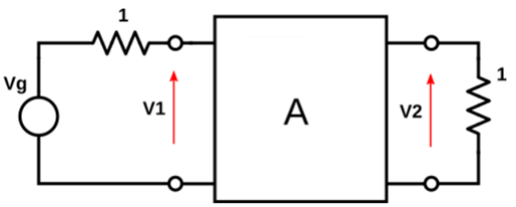

##Obtener impedancia de entrada, sintetizar como un cuadripolo escalera, modificar para una frecuencia de corte $2 π 10^6$ rad/s y resistencia de generador 50$Ω$:

In [9]:
import numpy as np
import sympy as sp
from IPython.display import display, Math

def mostrar_ecuacion(nombre, expr, decimales=4):
    expr_redondeada = expr.xreplace({n: round(n, decimales) for n in expr.atoms(sp.Float)})
    display(Math(f"{nombre} = " + sp.latex(expr_redondeada)))

n = 3
ripple_db = 3.0
R_g = 1.0
R_L = 1.0

beta = np.log(1 / np.tanh(ripple_db / (20 * np.log10(np.e) * 2)))
gamma = np.sinh(beta / (2 * n))

a = [np.sin((2 * k - 1) * np.pi / (2 * n)) for k in range(1, n + 1)]
b = [gamma**2 + (np.sin(k * np.pi / n))**2 for k in range(1, n + 1)]

g = np.zeros(n + 1)
g[1] = 2 * a[0] / gamma
g[2] = (4 * a[0] * a[1]) / (b[0] * g[1])
g[3] = (4 * a[1] * a[2]) / (b[1] * g[2])

L1, C2, L3 = g[1], g[2], g[3]

print(f"--- Componentes normalizados (Ripple = {ripple_db} dB)\n")
print(f"L1 = {L1:.4f} H \n C2 = {C2:.4f} F \n L3 = {L3:.4f} H\n")

s = sp.Symbol('s')
Z3 = s * L3 + R_L
Y2 = s * C2 + 1 / Z3
Zin = sp.cancel(s * L1 + 1 / Y2)

num, den = sp.fraction(Zin)
termino_indep = den.subs(s, 0)
Zin_limpia = sp.Poly(num / termino_indep, s).as_expr() / sp.Poly(den / termino_indep, s).as_expr()

print("--- Impedancia de entrada normalizada\n")
mostrar_ecuacion("Z_{in}(s)", Zin_limpia, decimales=4)

wc = 2 * np.pi * 1e6
R_norm = 50.0

L1_d = (L1 * R_norm) / wc
C2_d = C2 / (R_norm * wc)
L3_d = (L3 * R_norm) / wc

print("\n--- Componentes desnormalizados (wc = 2π·10^6 rad/s, R = 50 Ω)\n")
print(f"L1' = {L1_d*1e6:.3f} uH")
print(f"C2' = {C2_d*1e12:.2f} pF")
print(f"L3' = {L3_d*1e6:.3f} uH")

--- Componentes normalizados (Ripple = 3.0 dB)

L1 = 3.3487 H 
 C2 = 0.7117 F 
 L3 = 3.3487 H

--- Impedancia de entrada normalizada



<IPython.core.display.Math object>


--- Componentes desnormalizados (wc = 2π·10^6 rad/s, R = 50 Ω)

L1' = 26.648 uH
C2' = 2265.41 pF
L3' = 26.648 uH


##Simulación en LTspice

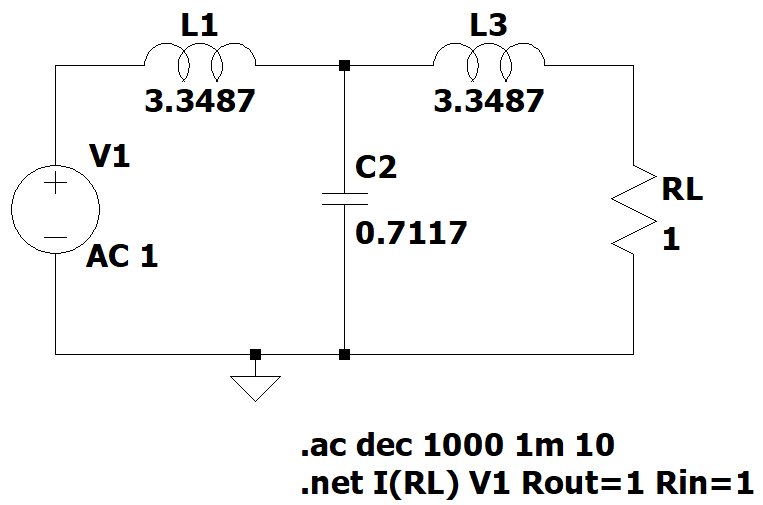

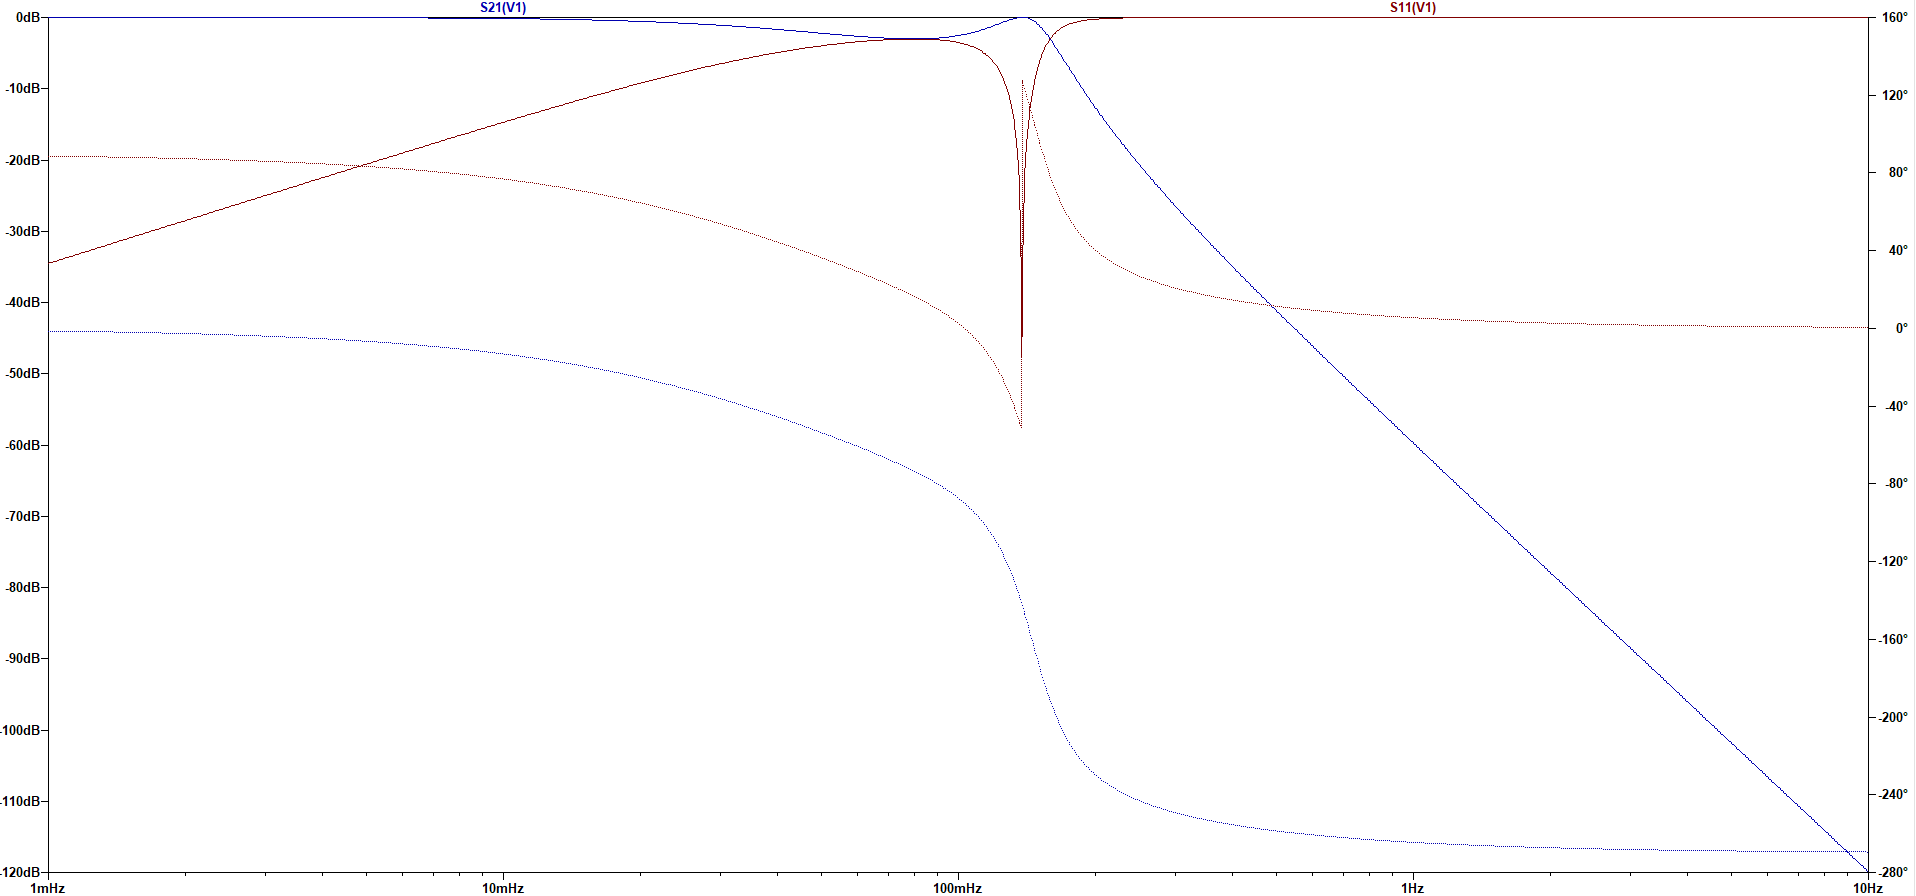

##Explicación del comportamiento a partir de los valores de $S_{11}$

Centro de la banda de paso ($\omega \in [0, 1]\text{ rad/s}$): El filtro presenta tres ceros de reflexión en $\omega = 0$ y $\omega = \frac{\sqrt{3}}{2} \approx 0.866\text{ rad/s}$ ($137.8\text{ mHz}$). En esas frecuencias, $Z_{in}(j\omega) = 1\ \Omega$, por lo que $S_{11} = 0$ ($-\infty\text{ dB}$ en escala logarítmica); hay adaptación perfecta y máxima transferencia de potencia hacia la carga ($\vert{}S_{21}\vert{} = 0\text{ dB}$). Entre los ceros (en $\omega = 0.5\text{ rad/s}$), se produce la máxima desadaptación permitida dentro de la banda de paso, donde $\vert{}S_{11}\vert{}$ alcanza un pico de $-3.01\text{ dB}$ (se refleja el $50\%$ de la potencia y pasa el $50\%$, equivalente a $-3\text{ dB}$ en $\vert{}S_{21}\vert{}$).   


Frecuencia de corte ($\omega_c = 1\text{ rad/s}$ / $f_c = 159.15\text{ mHz}$):
Es el límite del rizado equiripple. Aquí $\vert{}S_{11}(j1)\vert{}$ vuelve a alcanzar el valor máximo admisible de la banda de paso ($-3.01\text{ dB}$). La impedancia $Z_{in}(j1)$ adquiere una componente reactiva importante que impide que se transfiera el $100\%$ de la potencia disponible.   


Banda de transición y centro de la banda detenida ($\omega \gg 1\text{ rad/s}$):
A medida que la frecuencia supera $\omega_c$, la reactancia del inductor serie $L_1$ crece linealmente ($\omega L_1 \to \infty$) comportándose como un circuito abierto, mientras que la susceptancia del capacitor $C_2$ cortocircuita la señal a masa. En consecuencia, $Z_{in}(j\omega)$ se vuelve puramente imaginaria y tiende a infinito, haciendo que $\vert{}S_{11}(j\omega)\vert{} \to 1$ ($0\text{ dB}$). Como el cuadripolo no es disipativo, no absorbe calor: atenúa la señal a la salida ($\vert{}S_{21}\vert{} \to -\infty\text{ dB}$) reflejando casi el $100\%$ de la energía incidente de regreso hacia el generador.

#**Parte B:** Investigación sobre NANO VNA

Un Analizador de Redes Vectorial (VNA) es un instrumento diseñado para medir la magnitud y la fase de las ondas incidentes, reflejadas y transmitidas a través de un dispositivo bajo prueba, caracterizándolo en el dominio de la frecuencia mediante sus parámetros de dispersión S11, S21, S12 y S22. Su uso resulta fundamental al trabajar con frecuencias de RF y microondas, donde las longitudes de onda son comparables al tamaño físico del circuito. En estos escenarios, emplear puntas de prueba convencionales de osciloscopio desadapta y altera el sistema debido a su capacitancia parásita intrínseca. Además, el VNA es indispensable para diseñar redes de adaptación de 50 ohms en líneas de transmisión analizando la pérdida de retorno y el diagrama de Smith, así como para evaluar filtros caracterizando su respuesta en frecuencia con un alto rango dinámico.

Al contrastar un NanoVNA estándar con un osciloscopio digital (DSO) de laboratorio típico, como la serie GW Instek GDS-1000B o 2000E, las diferencias radican principalmente en sus arquitecturas y dominios de operación. Mientras el osciloscopio analiza señales en el dominio del tiempo mediante un muestreo de banda ancha con un conversor analógico-digital (ADC), el NanoVNA opera nativamente en frecuencia utilizando un barrido sintetizado y un receptor sintonizado. Esto le permite al NanoVNA alcanzar anchos de banda de 900 MHz o más, superando el límite habitual de 50 a 200 MHz de un DSO educativo. El rango dinámico también presenta una diferencia sustancial; el NanoVNA logra entre 70 dB y 90 dB en bandas bajas gracias a un filtro estrecho que rechaza el ruido, superando los 40 a 48 dB del ADC de 8 bits del osciloscopio, el cual tiene grandes dificultades para registrar simultáneamente señales de amplitudes muy dispares. En cuanto a la impedancia de entrada, el VNA se mantiene en 50 ohms constantes para evitar reflexiones en sistemas coaxiales, a diferencia del osciloscopio, cuya alta impedancia de 1 Mohm en paralelo con 15 pF representa una carga severa para el circuito a medida que aumenta la frecuencia.

A pesar de operar de forma nativa en frecuencia, el NanoVNA permite realizar mediciones en el dominio del tiempo mediante la función de Reflectometría en el Dominio del Tiempo (TDR). Para lograrlo, el equipo mide el vector complejo a lo largo de un barrido de frecuencias y le aplica matemáticamente la Transformada Inversa Rápida de Fourier (IFFT) directamente en su microcontrolador. A través de este proceso, el instrumento simula la respuesta al impulso o al escalón del sistema en función del tiempo o de la distancia física. Esta capacidad resulta sumamente útil para detectar la ubicación exacta de discontinuidades de impedancia, fallas o cortocircuitos a lo largo de una línea de transmisión, además de permitir la medición precisa de la longitud eléctrica de un cable.